<a href="https://colab.research.google.com/github/DrDourado/ME_640_Optimum_Design_Fall_2026/blob/main/ME_640_08_RBDO_Fundamentals_FORM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ME 640 — Reliability-Based Design Optimization
## Lecture 1 — Reliability Fundamentals, Limit States, Reliability Index, and FORM

### Objectives
Define RBDO; formulate a limit-state function; relate failure probability, reliability and reliability index; interpret the reliability index geometrically; formulate FORM; locate the Most Probable Point (MPP); and recognize FORM assumptions and limitations.

Throughout:
$$
g(\mathbf X)>0:\text{ safe},\quad g(\mathbf X)=0:\text{ limit state},\quad g(\mathbf X)<0:\text{ failure}.
$$

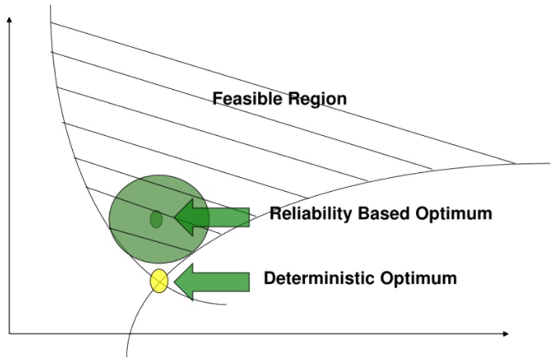

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.optimize import minimize
np.random.seed(640)
plt.rcParams["figure.figsize"]=(7,5)

# 1. From deterministic design to RBDO
A deterministic problem commonly enforces
$$
g_j(\mathbf d,\mathbf x)\ge0.
$$
Real systems contain uncertainty in loads, material properties, dimensions, environment, manufacturing, and models. A nominally feasible design can therefore fail.

Reliability-Based Design Optimization explicitly constrains failure probability:
$$
\begin{aligned}
\min_{\mathbf d}\quad&C(\mathbf d)\\
\mathrm{s.t.}\quad&P[g_j(\mathbf d,\mathbf X)\le0]\le P_{f,j}^{target},\\
&\mathbf d^L\le\mathbf d\le\mathbf d^U.
\end{aligned}
$$
The objective remains engineering economy/performance, but feasibility becomes probabilistic.

# 2. Limit-state function
A useful interpretation is
$$
g=\text{capacity}-\text{demand}.
$$
For resistance \(R\) and load \(S\):
$$
g(R,S)=R-S.
$$
Failure occurs when $S>R$. The surface $g=0$ separates safe and failed regions.

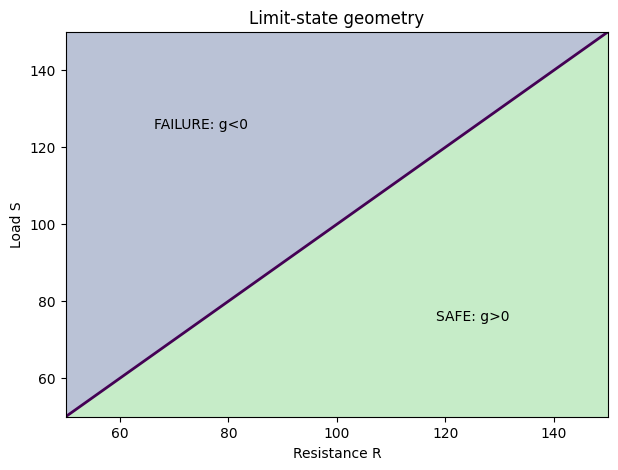

In [2]:
R=np.linspace(50,150,250); S=np.linspace(50,150,250)
RR,SS=np.meshgrid(R,S); G=RR-SS
fig,ax=plt.subplots()
ax.contourf(RR,SS,G,levels=[-100,0,100],alpha=.35)
ax.contour(RR,SS,G,levels=[0],linewidths=2)
ax.text(125,75,"SAFE: g>0",ha="center"); ax.text(75,125,"FAILURE: g<0",ha="center")
ax.set(xlabel="Resistance R",ylabel="Load S",title="Limit-state geometry")
plt.show()

# 3. Failure probability, reliability, and $\beta$
$$
P_f=P[G(\mathbf X)\le0],\qquad R=1-P_f.
$$
The generalized reliability index is related to failure probability by
$$
\boxed{\beta=-\Phi^{-1}(P_f)},\qquad P_f=\Phi(-\beta).
$$

### Special linear/normal interpretation
If the margin itself is Gaussian,
$
g\sim\mathcal N(\mu_g,\sigma_g^2),
$
then
$$
\boxed{\beta=\frac{\mu_g}{\sigma_g}}.
$$
Thus $\beta$ is the number of standard deviations separating the mean safety margin from failure.

**Important:** $\mu_g/\sigma_g$ is exact for this Gaussian-margin setting. FORM generalizes the geometric idea for nonlinear/nontrivial problems.

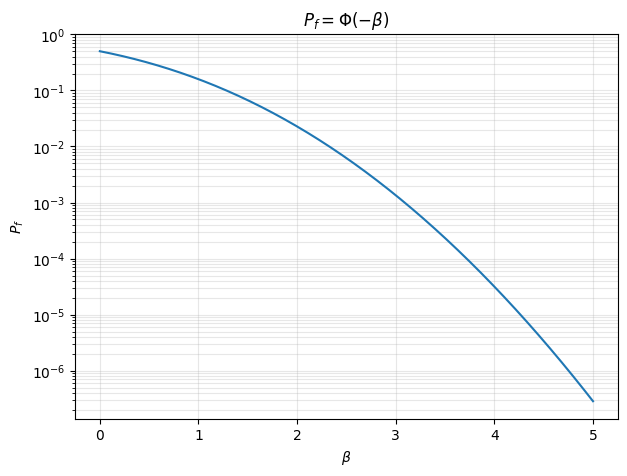

,beta,Pf
0,1.0,0.158655
1,2.0,0.022750
2,3.0,0.001350
3,3.5,0.000233
4,4.0,0.000032


In [3]:
b=np.linspace(0,5,300)
fig,ax=plt.subplots(); ax.semilogy(b,norm.cdf(-b))
ax.set(xlabel=r"$\beta$",ylabel=r"$P_f$",title=r"$P_f=\Phi(-\beta)$")
ax.grid(True,which="both",alpha=.3); plt.show()
display(pd.DataFrame({"beta":[1,2,3,3.5,4],"Pf":norm.cdf(-np.array([1,2,3,3.5,4]))}))

# 4. Exact linear-Gaussian example
Let
$
R\sim\mathcal N(120,10^2),\qquad S\sim\mathcal N(80,12^2),
$
independently. For $g=R-S$,
$$
\mu_g=\mu_R-\mu_S,\qquad
\sigma_g=\sqrt{\sigma_R^2+\sigma_S^2},
$$
so
$$
\beta=\frac{\mu_R-\mu_S}{\sqrt{\sigma_R^2+\sigma_S^2}}.
$$

beta = 2.5607375986579197  Pf = 0.5222510692482107 %


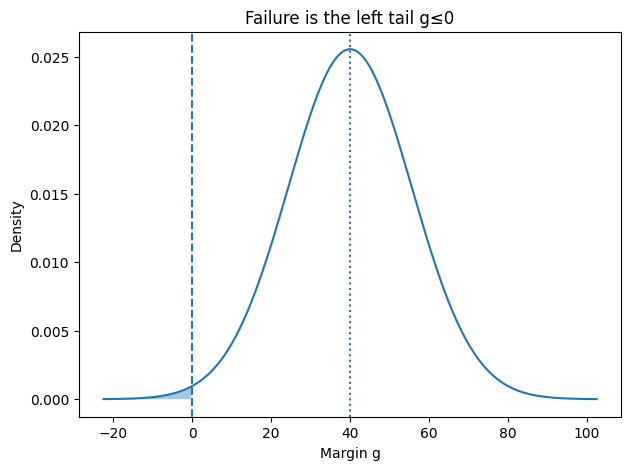

In [9]:
muR,sR,muS,sS=120,10,80,12
mg=muR-muS; sg=np.sqrt(sR**2+sS**2); beta=mg/sg
print("beta =",beta," Pf =",norm.cdf(-beta)*100,"%")
x=np.linspace(mg-4*sg,mg+4*sg,500); p=norm.pdf(x,mg,sg)
fig,ax=plt.subplots(); ax.plot(x,p); ax.fill_between(x,p,where=x<=0,alpha=.4)
ax.axvline(0,ls="--"); ax.axvline(mg,ls=":")
ax.set(xlabel="Margin g",ylabel="Density",title="Failure is the left tail g≤0"); plt.show()

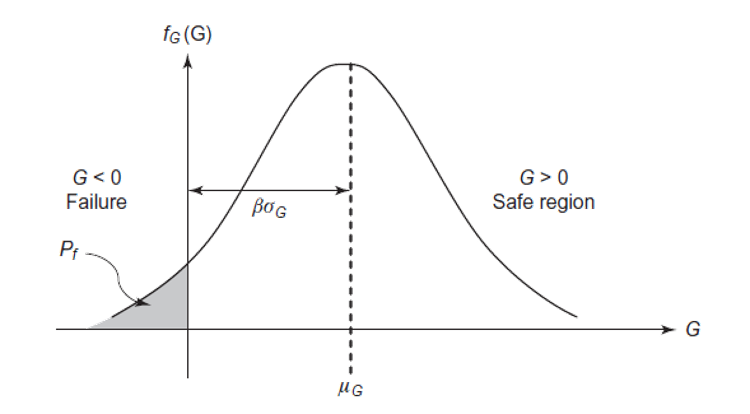

# 5. Standard-normal space: geometric meaning
For independent Gaussian variables,
$$
u_i=\frac{x_i-\mu_{x_i}}{\sigma_{x_i}},\qquad \mathbf U\sim\mathcal N(\mathbf0,\mathbf I).
$$
After transforming the limit state to $G(\mathbf U)=0$, FORM finds
$$
\boxed{\mathbf u^*=\arg\min_{\mathbf u}\|\mathbf u\|\quad\mathrm{s.t.}\quad G(\mathbf u)=0}
$$
and
$$
\boxed{\beta=\|\mathbf u^*\|}.
$$
$\mathbf u^*$ is the **Most Probable Point (MPP)** or design point: the point on the failure boundary closest to the origin of standard-normal space.

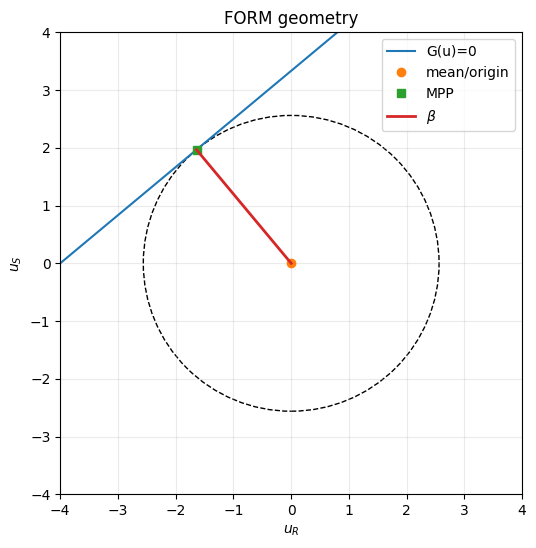

In [5]:
u=np.linspace(-4,4,300); us=(mg+sR*u)/sS
a=np.array([sR,-sS]); uss=-mg*a/(a@a)
fig,ax=plt.subplots(figsize=(6,6)); ax.plot(u,us,label="G(u)=0")
ax.add_patch(plt.Circle((0,0),np.linalg.norm(uss),fill=False,ls="--"))
ax.plot(0,0,"o",label="mean/origin"); ax.plot(*uss,"s",label="MPP")
ax.plot([0,uss[0]],[0,uss[1]],lw=2,label=r"$\beta$")
ax.set(xlim=(-4,4),ylim=(-4,4),xlabel=r"$u_R$",ylabel=r"$u_S$",title="FORM geometry")
ax.set_aspect("equal"); ax.grid(alpha=.25); ax.legend(); plt.show()

# 6. First-Order Reliability Method (FORM)
FORM:
1. defines $g(\mathbf X)$;
2. specifies distributions;
3. transforms $\mathbf X\to\mathbf U, \qquad u_i=\frac{x_i-\mu_{x_i}}{\sigma_{x_i}}$;
4. finds the MPP on $G=0$;
5. sets $\beta=\|\mathbf u^*\|$;
6. approximates
$
P_f\approx\Phi(-\beta).
$

“First-order” refers to the tangent/linear approximation of the limit-state surface at the MPP. This can be highly efficient, but strong curvature, multiple failure regions, or difficult non-Gaussian transformations can reduce accuracy.

# 7. Nonlinear FORM illustration
Consider
$$
G(u_1,u_2)=5-u_1-\frac12u_2^2.
$$
Because $u_1,u_2$ are already standard normal, FORM directly solves the constrained minimum-distance problem.

MPP = [1.00007039 2.82840224]  beta = 3.000000001331705  Pf_FORM = 0.13498980257281792 %


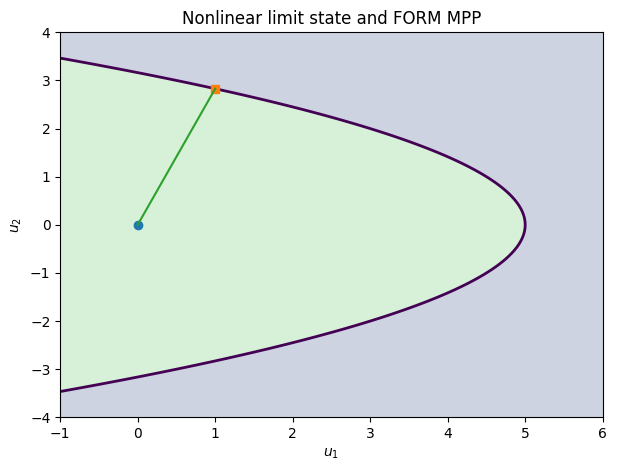

In [10]:
def G(u): return 5-u[0]-.5*u[1]**2
r=minimize(lambda u:u@u,[2,2],constraints={"type":"eq","fun":G},method="SLSQP")
ustar=r.x; bf=np.linalg.norm(ustar)
print("MPP =",ustar," beta =",bf," Pf_FORM =",norm.cdf(-bf)*100,"%")
u1=np.linspace(-1,6,350);u2=np.linspace(-4,4,350);U1,U2=np.meshgrid(u1,u2)
fig,ax=plt.subplots(); ax.contourf(U1,U2,5-U1-.5*U2**2,levels=[-20,0,20],alpha=.25)
ax.contour(U1,U2,5-U1-.5*U2**2,levels=[0],linewidths=2)
ax.plot(0,0,"o");ax.plot(*ustar,"s");ax.plot([0,ustar[0]],[0,ustar[1]])
ax.set(xlabel=r"$u_1$",ylabel=r"$u_2$",title="Nonlinear limit state and FORM MPP");plt.show()

# 8. Bridge to RBDO
Reliability analysis asks: **for a fixed design, how reliable is it?**

RBDO asks:
$$
\min_{\mathbf d}C(\mathbf d)
\quad\mathrm{s.t.}\quad
\beta_j(\mathbf d)\ge\beta_j^{target}.
$$

Classical FORM-based RBDO naturally forms a **double loop**:
- outer loop: optimize design;
- inner loop: perform FORM for each candidate.



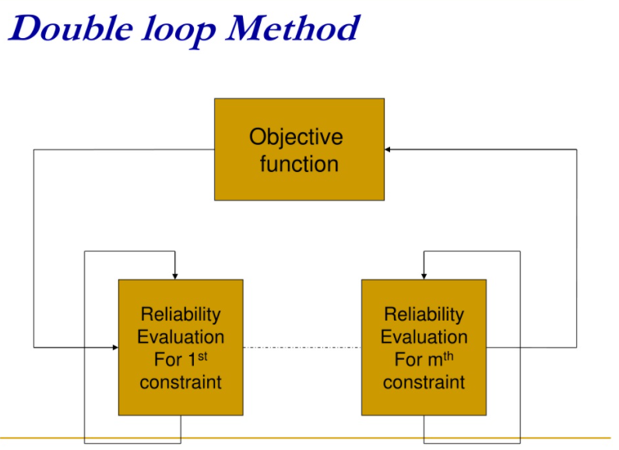

### Key takeaways
- Limit states define failure explicitly.
- $\beta=\mu_g/\sigma_g$ has an intuitive standardized-margin interpretation in the Gaussian case.
- FORM generalizes reliability geometrically through the MPP.
- RBDO embeds reliability analysis into optimization.